# Pergunta 4 — Inclusão em classes comuns nas redes pública e privada

**Pergunta:** Qual a parcela das matrículas da educação especial em classes comuns, e como ela difere entre as redes pública e privada?

A comparação considera **2015, 2020 e 2025** e utiliza os dados nacionais das *Sinopses Estatísticas da Educação Básica*, do INEP. As matrículas foram agrupadas por rede e por tipo de classe (comum ou exclusiva).

## 1. Dados utilizados

A base contém apenas seis registros: duas redes de ensino em cada um dos três anos. As contagens foram extraídas das linhas do **Brasil** nas tabelas oficiais.

- **2015 e 2020:** tabelas **1.40** (classes comuns) e **1.46** (classes exclusivas), somando as áreas urbana e rural e as dependências federal, estadual e municipal para formar a rede pública.
- **2025:** tabelas **1.61** (classes comuns) e **1.68** (classes exclusivas), usando as colunas *Rede Pública* e *Rede Privada*.

O arquivo `pergunta4_dados_limpos_inep.csv` fica na mesma pasta que este notebook.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

arquivo = Path("pergunta4_dados_limpos_inep.csv")
if not arquivo.exists():
    raise FileNotFoundError(
        "Coloque pergunta4_dados_limpos_inep.csv na mesma pasta do notebook."
    )

dados = pd.read_csv(arquivo, encoding="utf-8-sig")

# Verifica se há uma linha para cada rede em cada ano.
assert set(dados["ano"]) == {2015, 2020, 2025}
assert set(dados["rede"]) == {"Pública", "Privada"}
assert not dados.duplicated(["ano", "rede"]).any()
assert len(dados) == 6
assert dados[["classes_comuns", "classes_exclusivas"]].ge(0).all().all()

dados["total_matriculas"] = (
    dados["classes_comuns"] + dados["classes_exclusivas"]
)

# Confere os totais nacionais das Sinopses.
matriculas_nacionais = dados.groupby("ano")["total_matriculas"].sum()
assert matriculas_nacionais.to_dict() == {
    2015: 930683, 2020: 1308900, 2025: 2458159
}

print("Dados carregados e totais nacionais conferidos.")
display(dados.sort_values(["ano", "rede"]).reset_index(drop=True))

Dados carregados e totais nacionais conferidos.


,ano,rede,classes_comuns,classes_exclusivas,total_matriculas
0,2015,Privada,47364,131572,178936
1,2015,Pública,703619,48128,751747
2,2020,Privada,81101,117295,198396
3,2020,Pública,1071774,38730,1110504
4,2025,Privada,232753,119374,352127
5,2025,Pública,2065252,40780,2106032


## 2. Percentual de matrículas em classes comuns

Para cada rede e ano, o percentual é calculado dividindo as matrículas em classes comuns pelo total de matrículas da educação especial naquela rede. Isso evita comparar apenas números absolutos de redes com tamanhos diferentes.

In [2]:
dados["percentual_comuns"] = (
    100 * dados["classes_comuns"] / dados["total_matriculas"]
)

comparacao = dados.pivot(
    index="ano", columns="rede", values="percentual_comuns"
).sort_index()

# Diferença entre os percentuais das redes, medida em pontos percentuais.
comparacao["Diferença (p.p.)"] = (
    comparacao["Pública"] - comparacao["Privada"]
)

print("Percentual de matrículas em classes comuns:")
display(comparacao.round(2))

Percentual de matrículas em classes comuns:


rede,Privada,Pública,Diferença (p.p.)
ano,,,
2015,26.47,93.60,67.13
2020,40.88,96.51,55.63
2025,66.10,98.06,31.96


## 3. Visualização — evolução por rede

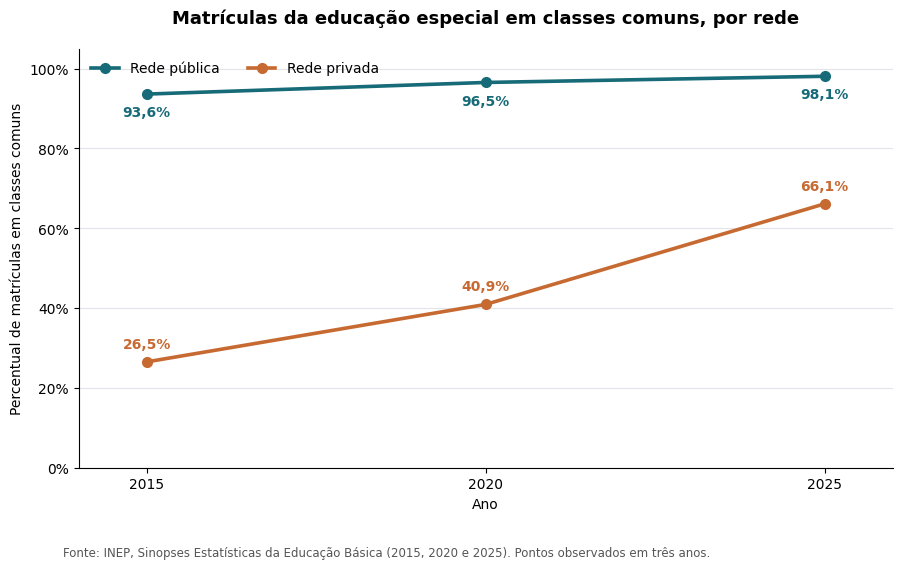

In [3]:
anos = [2015, 2020, 2025]
cores = {"Pública": "#176B78", "Privada": "#C76A32"}

fig, ax = plt.subplots(figsize=(10.5, 5.9))

for rede in ["Pública", "Privada"]:
    valores = dados.loc[dados["rede"] == rede].sort_values("ano")
    ax.plot(
        valores["ano"], valores["percentual_comuns"],
        color=cores[rede], linewidth=2.6, marker="o", markersize=7,
        label=f"Rede {rede.lower()}"
    )
    # Os rótulos mostram os valores observados, sem sugerir medições anuais.
    for _, linha in valores.iterrows():
        deslocamento = -16 if rede == "Pública" else 10
        ax.annotate(
            f'{linha["percentual_comuns"]:.1f}%'.replace('.', ','),
            (linha["ano"], linha["percentual_comuns"]),
            xytext=(0, deslocamento), textcoords="offset points",
            ha="center", fontsize=10, color=cores[rede], fontweight="semibold"
        )

ax.set_title("Matrículas da educação especial em classes comuns, por rede", fontsize=13, weight="bold", pad=18)
ax.set_xlabel("Ano")
ax.set_ylabel("Percentual de matrículas em classes comuns")
ax.set_xticks(anos)
ax.set_xlim(2014, 2026)
ax.set_ylim(0, 105)
ax.set_yticks(range(0, 101, 20))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0f}%"))
ax.grid(axis="y", color="#E1E5E9")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=10)

fig.text(
    0.11, 0.01,
    "Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025). "
    "Pontos observados em três anos.",
    fontsize=8.5, color="#555555"
)
fig.subplots_adjust(bottom=0.16, top=0.87)
plt.savefig("pergunta4_grafico_redes.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Leitura dos resultados

O percentual de matrículas da educação especial em classes comuns aumentou nas duas redes entre 2015 e 2025. **Na rede pública, passou de 93,6% para 98,1%; na privada, de 26,5% para 66,1%.**

A diferença entre as redes diminuiu, mas continuou relevante em 2025. Os dados mostram como as matrículas se distribuem entre classes comuns e exclusivas; **não medem, sozinhos, a qualidade do atendimento ou as condições de inclusão**.

A rede privada reúne instituições de diferentes perfis, inclusive aquelas com oferta especializada em classes exclusivas. Isso deve ser levado em conta ao interpretar a distância entre as duas redes.

In [4]:
inicio = comparacao.loc[2015]
fim = comparacao.loc[2025]

print(f"Rede pública: {inicio['Pública']:.1f}% (2015) → {fim['Pública']:.1f}% (2025)")
print(f"Rede privada: {inicio['Privada']:.1f}% (2015) → {fim['Privada']:.1f}% (2025)")
print(
    f"Diferença entre redes: {inicio['Diferença (p.p.)']:.1f} p.p. (2015) "
    f"→ {fim['Diferença (p.p.)']:.1f} p.p. (2025)"
)

Rede pública: 93.6% (2015) → 98.1% (2025)
Rede privada: 26.5% (2015) → 66.1% (2025)
Diferença entre redes: 67.1 p.p. (2015) → 32.0 p.p. (2025)


### Limitações e fonte

Os três anos representam **pontos de observação**, não uma série anual completa. A comparação usa registros de matrículas, não o número de indivíduos, e não permite afirmar a causa das diferenças entre as redes. Possíveis alterações nos critérios de coleta entre as edições do Censo Escolar também devem ser consideradas.

**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica). A extração foi feita nas tabelas 1.40/1.46 (2015 e 2020) e 1.61/1.68 (2025).